<a href="https://colab.research.google.com/github/winwinjong-gif/Machin-Learning-report/blob/main/week5/DL_regression_image.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn import datasets, metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
digits = datasets.load_digits()

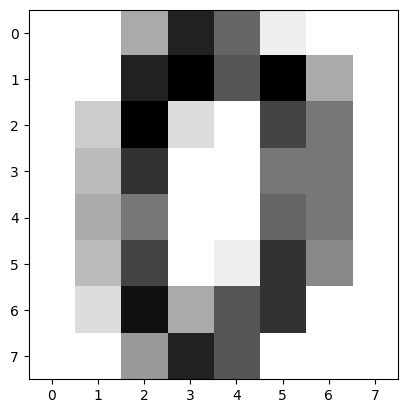

In [19]:
plt.imshow(
    digits.images[0],
    cmap=plt.cm.gray_r,
    interpolation='nearest'
)

In [20]:
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))
data

array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ..., 10.,  0.,  0.],
       [ 0.,  0.,  0., ..., 16.,  9.,  0.],
       ...,
       [ 0.,  0.,  1., ...,  6.,  0.,  0.],
       [ 0.,  0.,  2., ..., 12.,  0.,  0.],
       [ 0.,  0., 10., ..., 12.,  1.,  0.]])

In [21]:
X = digits.data
y = digits.target


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y , test_size=0.2
)

In [23]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [24]:
model = tf.keras.Sequential()
model.add(tf.keras.layers.Dense(32, activation="relu", input_shape=(64,)))
model.add(tf.keras.layers.Dense(16, activation="relu"))
model.add(tf.keras.layers.Dense(1))

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [25]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,625 (10.25 KB)

 Trainable params: 2,625 (10.25 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_split=0.2, verbose=1)

Epoch 1/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 17.7018 - mae: 3.3661 - val_loss: 10.8597 - val_mae: 2.6063
Epoch 2/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 9.4878 - mae: 2.5352 - val_loss: 6.2881 - val_mae: 2.0549
Epoch 3/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.6688 - mae: 1.9546 - val_loss: 4.3526 - val_mae: 1.6575
Epoch 4/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.9250 - mae: 1.5627 - val_loss: 3.4620 - val_mae: 1.4460
Epoch 5/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3.0706 - mae: 1.3317 - val_loss: 2.9764 - val_mae: 1.3101
Epoch 6/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.5912 - mae: 1.1975 - val_loss: 2.7140 - val_mae: 1.2265
Epoch 7/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.2892 - mae: 1.1094 - val_loss: 2.5629 - val_mae: 1.1804
Epoch 8/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.0687 - mae: 1.0449 - val_loss: 2.3791 - val_mae: 1.1139
Epoch 9/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.8

In [35]:
y_prob = model.predict(X_test).flatten()

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


In [36]:
mae = mean_absolute_error(y_test, y_prob)
print("MAE =", mae)
mse= mean_squared_error(y_test, y_prob)
print("MSE =", mse)

MAE = 0.736993670463562
MSE = 1.2079862356185913


In [37]:
result = pd.DataFrame({"실제 숫자": y_test, "예측 숫자": y_prob})
print("\n실제값과 예측값 비교")
print(result.head())


실제값과 예측값 비교
   실제 숫자     예측 숫자
0      6  6.514763
1      6  6.453482
2      5  4.401086
3      3  3.972369
4      5  6.658701
